# UFO reporting-country exercise

Run from this directory. The shared `ufo_app.py` implements the same cleaning and training used by the Flask challenge. We retain 1–60 second reports with known countries and valid coordinates, split before fitting, and standardize inside a pipeline. Unlike the original demonstration, we stratify the split and report macro F1 as well as accuracy.

In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from ufo_app import DATASET, FEATURES, clean_data, train_model

raw = pd.read_csv(DATASET)
rows = clean_data(raw)
print(f"Raw rows: {len(raw)}; retained: {len(rows)}; removed: {len(raw) - len(rows)}")
display(rows.head())
display(rows.Country.value_counts())
assert rows[FEATURES].notna().all().all()

Raw rows: 80332; retained: 25863; removed: 54469


,Seconds,Latitude,Longitude,Country
2,20.0,53.200000,-2.916667,gb
3,20.0,28.978333,-96.645833,us
14,30.0,35.823889,-80.253611,us
23,60.0,45.582778,-122.352222,us
24,3.0,51.783333,-0.783333,gb


Country
us    23612
ca     1266
gb      742
au      202
de       41
Name: count, dtype: int64

In [2]:
model, encoder, metrics, X_test, y_test, predicted = train_model()
display(pd.Series(metrics, name="Evaluation"))
print(classification_report(y_test, predicted, zero_division=0))
print("Label encoding:", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))
assert model.named_steps["standardscaler"].n_samples_seen_ == metrics["train_rows"]
assert np.isfinite(list(metrics.values())).all()

rows                 25863.000000
train_rows           20690.000000
test_rows             5173.000000
accuracy                 0.961531
macro_f1                 0.687819
majority_accuracy        0.913010
Name: Evaluation, dtype: float64

              precision    recall  f1-score   support

          au       1.00      1.00      1.00        40
          ca       0.76      0.36      0.49       253
          de       0.00      0.00      0.00         8
          gb       0.95      1.00      0.97       149
          us       0.97      0.99      0.98      4723

    accuracy                           0.96      5173
   macro avg       0.74      0.67      0.69      5173
weighted avg       0.95      0.96      0.95      5173

Label encoding: {'au': 0, 'ca': 1, 'de': 2, 'gb': 3, 'us': 4}


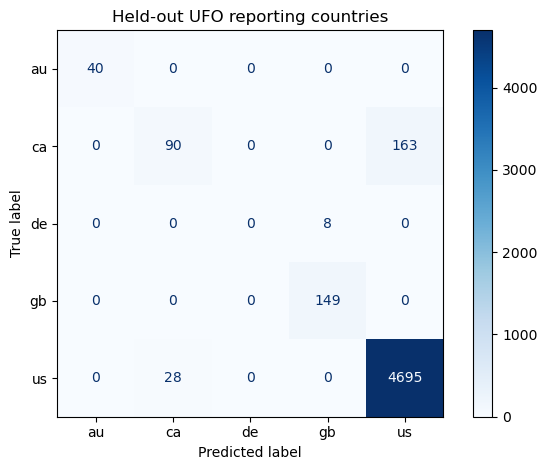

In [3]:
ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=encoder.classes_, cmap="Blues")
plt.title("Held-out UFO reporting countries")
plt.tight_layout()
plt.show()

## Export and reload

Save the pipeline and encoder together so country IDs cannot become detached from their labels. Only reload this locally generated pickle. The Flask challenge trains in memory instead; the pumpkin assignment demonstrates loading a saved model in a web app.

In [4]:
path = Path("ufo-model.pkl")
with path.open("wb") as stream:
    pickle.dump((model, encoder), stream)
with path.open("rb") as stream:
    restored_model, restored_encoder = pickle.load(stream)
np.testing.assert_array_equal(restored_model.predict(X_test), model.predict(X_test))
np.testing.assert_array_equal(restored_encoder.classes_, encoder.classes_)
sample = pd.DataFrame([[50, 44, -12]], columns=FEATURES)
print("Sample prediction:", restored_encoder.inverse_transform(restored_model.predict(sample))[0])
print("Export/reload predictions match on all held-out rows.")

Sample prediction: de
Export/reload predictions match on all held-out rows.


## Interpretation

Compare accuracy with the majority-class baseline and inspect macro F1: US reports dominate the dataset, and minority-country recall can remain poor despite high overall accuracy. Coordinates already contain most of the information about country; this is an integration exercise, not evidence about UFOs. A geographic lookup is preferable for actual country identification. Random splitting may also place related reports in both sets; a time or geographic split would better test generalization. Predictions always choose one of the five known countries even for unsupported locations.